<a href="https://colab.research.google.com/github/ankirani/Pinjol-Analysis/blob/main/Pinjol_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Load the Dataset

In [2]:
df = pd.read_csv("/content/midexam_indonesian_pinjol_analyst_dataset.csv", sep=None, engine="python")
print(df.head())

  Transaction_ID Platform_Name  Borrower_Age    Borrower_Income  \
0   TXN-20260001     PinjamYuk          59.0     Factory Worker   
1   TXN-20260002    PinjolCair          37.0                NaN   
2   TXN-20260003  KreditPintar          22.0     Factory Worker   
3   TXN-20260004     DanaCepat          65.0  Gojek/Grab Driver   
4   TXN-20260005       AdaKami          41.0    Corporate Admin   

         Loan_Purpose  Principal_IDR  Tenor_Days  Daily_Interest_Rate_Pct  \
0  Pay Off Other Debt      5000000.0        14.0                     0.11   
1  Pay Off Other Debt      1500000.0        60.0                      NaN   
2         Daily Needs      5000000.0        30.0                     0.12   
3         Daily Needs       500000.0        30.0                     0.12   
4    Business Capital      5000000.0        30.0                     0.19   

   Admin_Fee_IDR  Late_Penalty_IDR  Total_Repayment_IDR Disbursal_Date  \
0       250000.0               NaN            5797193.0     

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Transaction_ID           500 non-null    object 
 1   Platform_Name            447 non-null    object 
 2   Borrower_Age             451 non-null    float64
 3   Borrower_Income          436 non-null    object 
 4   Loan_Purpose             452 non-null    object 
 5   Principal_IDR            443 non-null    float64
 6   Tenor_Days               444 non-null    float64
 7   Daily_Interest_Rate_Pct  454 non-null    float64
 8   Admin_Fee_IDR            445 non-null    float64
 9   Late_Penalty_IDR         450 non-null    float64
 10  Total_Repayment_IDR      452 non-null    float64
 11  Disbursal_Date           463 non-null    object 
 12  Due_Date                 446 non-null    object 
 13  Loan_Status              455 non-null    object 
dtypes: float64(7), object(7)
m

Checking Missing Values

In [4]:
print("Missing values before Imputation :")
print(df.isnull().sum())

Missing values before Imputation :
Transaction_ID              0
Platform_Name              53
Borrower_Age               49
Borrower_Income            64
Loan_Purpose               48
Principal_IDR              57
Tenor_Days                 56
Daily_Interest_Rate_Pct    46
Admin_Fee_IDR              55
Late_Penalty_IDR           50
Total_Repayment_IDR        48
Disbursal_Date             37
Due_Date                   54
Loan_Status                45
dtype: int64


In [5]:
df.describe(include="all")

,Transaction_ID,Platform_Name,Borrower_Age,Borrower_Income,Loan_Purpose,Principal_IDR,Tenor_Days,Daily_Interest_Rate_Pct,Admin_Fee_IDR,Late_Penalty_IDR,Total_Repayment_IDR,Disbursal_Date,Due_Date,Loan_Status
count,500,447,451.000000,436,452,4.430000e+02,444.000000,454.000000,445.000000,4.500000e+02,4.520000e+02,463,446,455
unique,500,7,NaN,6,5,NaN,NaN,NaN,NaN,NaN,NaN,19,19,3
top,TXN-20260500,PinjolCair,NaN,Gojek/Grab Driver,Daily Needs,NaN,NaN,NaN,NaN,NaN,NaN,2026-02-16,2026-03-25,Defaulted
freq,1,81,NaN,81,107,NaN,NaN,NaN,NaN,NaN,NaN,34,32,158
mean,NaN,NaN,41.623060,NaN,NaN,2.057562e+06,48.963964,0.599427,165955.056180,3.355764e+05,3.195060e+06,NaN,NaN,NaN
std,NaN,NaN,14.239532,NaN,NaN,1.653723e+06,29.532223,0.621555,183668.627267,5.955239e+05,2.881525e+06,NaN,NaN,NaN
min,NaN,NaN,18.000000,NaN,NaN,5.000000e+05,14.000000,0.100000,25000.000000,0.000000e+00,5.320000e+05,NaN,NaN,NaN
25%,NaN,NaN,28.000000,NaN,NaN,1.000000e+06,14.000000,0.170000,50000.000000,0.000000e+00,1.264851e+06,NaN,NaN,NaN
50%,NaN,NaN,42.000000,NaN,NaN,1.500000e+06,60.000000,0.250000,100000.000000,1.386585e+05,2.098114e+06,NaN,NaN,NaN
75%,NaN,NaN,54.500000,NaN,NaN,2.000000e+06,90.000000,1.170000,250000.000000,3.908010e+05,4.586088e+06,NaN,NaN,NaN


In [6]:
#examine categorical variable
for col in ["Platform_Name", "Borrower_Income",
            "Loan_Purpose", "Loan_Status"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


Platform_Name
Platform_Name
PinjolCair      81
PinjamYuk       74
KreditPintar    72
DanaCepat       58
DanaKilat       56
AdaKami         55
NaN             53
RupiahCepat     51
Name: count, dtype: int64

Borrower_Income
Borrower_Income
Gojek/Grab Driver    81
Unemployed           80
Factory Worker       73
Freelancer           71
MSME Food Stall      69
NaN                  64
Corporate Admin      62
Name: count, dtype: int64

Loan_Purpose
Loan_Purpose
Daily Needs           107
Pay Off Other Debt    104
Business Capital       89
Medical Emergency      78
Lifestyle/Gadget       74
NaN                    48
Name: count, dtype: int64

Loan_Status
Loan_Status
Defaulted       158
Paid on Time    153
Late            144
NaN              45
Name: count, dtype: int64


Impute Missing Values

In [7]:
#impute missing value of numerical with median
#create a copy to preserve the original dataset
df_clean = df.copy()

# Numerical variables: median
numeric_cols = [
    "Borrower_Age",
    "Principal_IDR",
    "Daily_Interest_Rate_Pct",
    "Admin_Fee_IDR",
    "Total_Repayment_IDR",
    "Late_Penalty_IDR"
]

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

# Categorical variables: mode
categorical_cols = [
    "Platform_Name",
    "Borrower_Income",
    "Loan_Purpose",
    "Loan_Status"
]

for col in categorical_cols:
    mode_values = df_clean[col].mode(dropna=True)

    if not mode_values.empty:
        df_clean[col] = df_clean[col].fillna(
            mode_values.iloc[0]
        )

# Check remaining missing values
print(df_clean.isnull().sum())

Transaction_ID              0
Platform_Name               0
Borrower_Age                0
Borrower_Income             0
Loan_Purpose                0
Principal_IDR               0
Tenor_Days                 56
Daily_Interest_Rate_Pct     0
Admin_Fee_IDR               0
Late_Penalty_IDR            0
Total_Repayment_IDR         0
Disbursal_Date             37
Due_Date                   54
Loan_Status                 0
dtype: int64


Impute Missing Values for Disburcal Date, Due Date, and Tenor Days

In [8]:
#impute disburcal date, due date, and tenor days
#convert date columns to datetime
df_clean["Disbursal_Date"] = pd.to_datetime(
    df_clean["Disbursal_Date"], errors="coerce"
)
df_clean["Due_Date"] = pd.to_datetime(
    df_clean["Due_Date"], errors="coerce"
)

#ensure tenor is numeric
df_clean["Tenor_Days"] = pd.to_numeric(
    df_clean["Tenor_Days"], errors="coerce"
)

# fill missing Due_Date
mask_due = (
    df_clean["Due_Date"].isna()
    & df_clean["Disbursal_Date"].notna()
    & df_clean["Tenor_Days"].notna()
)

df_clean.loc[mask_due, "Due_Date"] = (
    df_clean.loc[mask_due, "Disbursal_Date"]
    + pd.to_timedelta(
        df_clean.loc[mask_due, "Tenor_Days"], unit="D"
    )
)

#fill missing Tenor_Days
mask_tenor = (
    df_clean["Tenor_Days"].isna()
    & df_clean["Disbursal_Date"].notna()
    & df_clean["Due_Date"].notna()
)

df_clean.loc[mask_tenor, "Tenor_Days"] = (
    df_clean.loc[mask_tenor, "Due_Date"]
    - df_clean.loc[mask_tenor, "Disbursal_Date"]
).dt.days

# 3. Fill missing Disbursal_Date
mask_disbursal = (
    df_clean["Disbursal_Date"].isna()
    & df_clean["Due_Date"].notna()
    & df_clean["Tenor_Days"].notna()
)

df_clean.loc[mask_disbursal, "Disbursal_Date"] = (
    df_clean.loc[mask_disbursal, "Due_Date"]
    - pd.to_timedelta(
        df_clean.loc[mask_disbursal, "Tenor_Days"], unit="D"
    )
)

# Check remaining missing values
print(df_clean[
    ["Disbursal_Date", "Due_Date", "Tenor_Days"]
].isnull().sum())

Disbursal_Date     7
Due_Date          14
Tenor_Days        13
dtype: int64


In [9]:
missing_data = df_clean[
    df_clean[
        ["Disbursal_Date", "Due_Date", "Tenor_Days"]
    ].isnull().any(axis=1)
]

display(missing_data)

,Transaction_ID,Platform_Name,Borrower_Age,Borrower_Income,Loan_Purpose,Principal_IDR,Tenor_Days,Daily_Interest_Rate_Pct,Admin_Fee_IDR,Late_Penalty_IDR,Total_Repayment_IDR,Disbursal_Date,Due_Date,Loan_Status
4,TXN-20260005,AdaKami,41.0,Corporate Admin,Business Capital,5000000.0,30.0,0.19,250000.0,1329545.0,6864545.0,NaT,NaT,Defaulted
8,TXN-20260009,DanaKilat,22.0,Gojek/Grab Driver,Daily Needs,1500000.0,NaN,1.81,225000.0,393025.0,3747025.0,NaT,2026-03-11,Late
36,TXN-20260037,PinjolCair,42.0,Factory Worker,Business Capital,2000000.0,NaN,1.52,300000.0,580838.0,4704838.0,2026-02-28,NaT,Late
93,TXN-20260094,PinjolCair,62.0,MSME Food Stall,Pay Off Other Debt,1000000.0,30.0,1.59,150000.0,378023.0,2005023.0,NaT,NaT,Late
120,TXN-20260121,PinjolCair,18.0,Gojek/Grab Driver,Business Capital,500000.0,NaN,1.35,75000.0,0.0,669500.0,2026-02-17,NaT,Paid on Time
156,TXN-20260157,PinjolCair,42.0,Gojek/Grab Driver,Daily Needs,2000000.0,NaN,1.14,300000.0,0.0,2098114.5,2026-02-16,NaT,Paid on Time
193,TXN-20260194,KreditPintar,42.0,MSME Food Stall,Business Capital,1500000.0,NaN,0.25,100000.0,445563.0,2200563.0,NaT,2026-03-26,Defaulted
223,TXN-20260224,PinjolCair,24.0,Unemployed,Business Capital,1000000.0,NaN,1.67,150000.0,0.0,1383800.0,2026-02-25,NaT,Paid on Time
273,TXN-20260274,PinjamYuk,30.0,Freelancer,Pay Off Other Debt,5000000.0,NaN,0.26,100000.0,0.0,2098114.5,2026-02-11,NaT,Paid on Time
302,TXN-20260303,AdaKami,23.0,Gojek/Grab Driver,Daily Needs,1000000.0,90.0,0.25,50000.0,138658.5,1249679.0,NaT,NaT,Late


Looking for Same Value



In [10]:
target = df_clean[
    df_clean["Disbursal_Date"].isna()
    & df_clean["Due_Date"].isna()
    & df_clean["Tenor_Days"].notna()
]

# Ambil transaksi referensi dengan platform,
# jumlah pinjaman, dan tenor yang sama
for idx, row in target.iterrows():
    candidates = df_clean[
        (df_clean["Platform_Name"] == row["Platform_Name"])
        & (df_clean["Principal_IDR"] == row["Principal_IDR"])
        & (df_clean["Tenor_Days"] == row["Tenor_Days"])
        & df_clean["Disbursal_Date"].notna()
        & df_clean["Due_Date"].notna()
    ]

    print(f"\nTarget index: {idx}")
    print("Transaction ID:", row["Transaction_ID"])

    if candidates.empty:
        print("Tidak ditemukan transaksi referensi yang cocok.")
    else:
        display(candidates[
            ["Transaction_ID", "Platform_Name",
             "Principal_IDR", "Tenor_Days",
             "Disbursal_Date", "Due_Date"]
        ])


Target index: 4
Transaction ID: TXN-20260005


,Transaction_ID,Platform_Name,Principal_IDR,Tenor_Days,Disbursal_Date,Due_Date
14,TXN-20260015,AdaKami,5000000.0,30.0,2026-02-15,2026-03-16
100,TXN-20260101,AdaKami,5000000.0,30.0,2026-02-28,2026-03-16
185,TXN-20260186,AdaKami,5000000.0,30.0,2026-02-14,2026-03-25
436,TXN-20260437,AdaKami,5000000.0,30.0,2026-02-23,2026-03-17
479,TXN-20260480,AdaKami,5000000.0,30.0,2026-02-26,2026-03-22



Target index: 93
Transaction ID: TXN-20260094


,Transaction_ID,Platform_Name,Principal_IDR,Tenor_Days,Disbursal_Date,Due_Date
24,TXN-20260025,PinjolCair,1000000.0,30.0,2026-02-21,2026-03-23
53,TXN-20260054,PinjolCair,1000000.0,30.0,2026-02-18,2026-03-10
96,TXN-20260097,PinjolCair,1000000.0,30.0,2026-02-24,2026-03-26
306,TXN-20260307,PinjolCair,1000000.0,30.0,2026-02-27,2026-03-28
334,TXN-20260335,PinjolCair,1000000.0,30.0,2026-02-26,2026-03-28
388,TXN-20260389,PinjolCair,1000000.0,30.0,2026-02-14,2026-03-16
452,TXN-20260453,PinjolCair,1000000.0,30.0,2026-02-21,2026-03-26



Target index: 302
Transaction ID: TXN-20260303


,Transaction_ID,Platform_Name,Principal_IDR,Tenor_Days,Disbursal_Date,Due_Date
188,TXN-20260189,AdaKami,1000000.0,90.0,2026-02-26,2026-03-25
202,TXN-20260203,AdaKami,1000000.0,90.0,2026-02-23,2026-05-24
212,TXN-20260213,AdaKami,1000000.0,90.0,2026-02-23,2026-03-12
228,TXN-20260229,AdaKami,1000000.0,90.0,2026-02-14,2026-03-12
256,TXN-20260257,AdaKami,1000000.0,90.0,2026-02-20,2026-03-18



Target index: 414
Transaction ID: TXN-20260415


,Transaction_ID,Platform_Name,Principal_IDR,Tenor_Days,Disbursal_Date,Due_Date
7,TXN-20260008,PinjolCair,5000000.0,14.0,2026-02-27,2026-03-15
10,TXN-20260011,PinjolCair,5000000.0,14.0,2026-02-27,2026-03-14
15,TXN-20260016,PinjolCair,5000000.0,14.0,2026-02-27,2026-03-26
44,TXN-20260045,PinjolCair,5000000.0,14.0,2026-02-28,2026-03-14
56,TXN-20260057,PinjolCair,5000000.0,14.0,2026-02-25,2026-03-19
152,TXN-20260153,PinjolCair,5000000.0,14.0,2026-02-23,2026-03-09
292,TXN-20260293,PinjolCair,5000000.0,14.0,2026-02-14,2026-03-12
312,TXN-20260313,PinjolCair,5000000.0,14.0,2026-03-11,2026-03-25
316,TXN-20260317,PinjolCair,5000000.0,14.0,2026-02-17,2026-03-03


In [11]:
# Check remaining missing values
print("Missing values per column:")
print(df_clean.isnull().sum())

# Display rows with missing dates or tenor
date_cols = ["Disbursal_Date", "Due_Date", "Tenor_Days"]

remaining_missing = df_clean[
    df_clean[date_cols].isnull().any(axis=1)
]

display(
    remaining_missing[
        ["Transaction_ID", "Platform_Name", "Principal_IDR",
         "Disbursal_Date", "Due_Date", "Tenor_Days"]
    ]
)

Missing values per column:
Transaction_ID              0
Platform_Name               0
Borrower_Age                0
Borrower_Income             0
Loan_Purpose                0
Principal_IDR               0
Tenor_Days                 13
Daily_Interest_Rate_Pct     0
Admin_Fee_IDR               0
Late_Penalty_IDR            0
Total_Repayment_IDR         0
Disbursal_Date              7
Due_Date                   14
Loan_Status                 0
dtype: int64


,Transaction_ID,Platform_Name,Principal_IDR,Disbursal_Date,Due_Date,Tenor_Days
4,TXN-20260005,AdaKami,5000000.0,NaT,NaT,30.0
8,TXN-20260009,DanaKilat,1500000.0,NaT,2026-03-11,NaN
36,TXN-20260037,PinjolCair,2000000.0,2026-02-28,NaT,NaN
93,TXN-20260094,PinjolCair,1000000.0,NaT,NaT,30.0
120,TXN-20260121,PinjolCair,500000.0,2026-02-17,NaT,NaN
156,TXN-20260157,PinjolCair,2000000.0,2026-02-16,NaT,NaN
193,TXN-20260194,KreditPintar,1500000.0,NaT,2026-03-26,NaN
223,TXN-20260224,PinjolCair,1000000.0,2026-02-25,NaT,NaN
273,TXN-20260274,PinjamYuk,5000000.0,2026-02-11,NaT,NaN
302,TXN-20260303,AdaKami,1000000.0,NaT,NaT,90.0


Check Inconsistent Value

In [12]:
check = df_clean[
    df_clean["Disbursal_Date"].notna()
    & df_clean["Due_Date"].notna()
    & df_clean["Tenor_Days"].notna()
].copy()

check["Calculated_Tenor"] = (
    check["Due_Date"] - check["Disbursal_Date"]
).dt.days

check["Tenor_Difference"] = (
    check["Calculated_Tenor"] - check["Tenor_Days"]
)

print("Total rows checked:", len(check))
print(
    "Recorded tenor shorter than date difference:",
    (check["Tenor_Difference"] > 0).sum()
)
print(
    "Recorded tenor longer than date difference:",
    (check["Tenor_Difference"] < 0).sum()
)
print(
    "Exactly consistent:",
    (check["Tenor_Difference"] == 0).sum()
)

display(
    check[
        ["Transaction_ID", "Disbursal_Date", "Due_Date",
         "Tenor_Days", "Calculated_Tenor", "Tenor_Difference"]
    ].head(20)
)

Total rows checked: 483
Recorded tenor shorter than date difference: 126
Recorded tenor longer than date difference: 235
Exactly consistent: 122


,Transaction_ID,Disbursal_Date,Due_Date,Tenor_Days,Calculated_Tenor,Tenor_Difference
0,TXN-20260001,2026-02-22,2026-03-28,14.0,34,20.0
1,TXN-20260002,2026-02-25,2026-03-22,60.0,25,-35.0
2,TXN-20260003,2026-02-19,2026-03-21,30.0,30,0.0
3,TXN-20260004,2026-02-25,2026-03-24,30.0,27,-3.0
5,TXN-20260006,2026-02-16,2026-05-17,90.0,90,0.0
6,TXN-20260007,2025-12-10,2026-03-10,90.0,90,0.0
7,TXN-20260008,2026-02-27,2026-03-15,14.0,16,2.0
9,TXN-20260010,2026-02-23,2026-03-23,14.0,28,14.0
10,TXN-20260011,2026-02-27,2026-03-14,14.0,15,1.0
11,TXN-20260012,2026-02-19,2026-03-21,30.0,30,0.0


In [13]:
#check consistent and inconsistent rows
check["Is_Consistent"] = (
    check["Calculated_Tenor"] == check["Tenor_Days"]
)

platform_check = check.groupby("Platform_Name").agg(
    Total_Rows=("Transaction_ID", "count"),
    Consistent_Rows=("Is_Consistent", "sum")
)

platform_check["Inconsistent_Rows"] = (
    platform_check["Total_Rows"]
    - platform_check["Consistent_Rows"]
)

platform_check["Consistency_Percentage"] = (
    platform_check["Consistent_Rows"]
    / platform_check["Total_Rows"] * 100
).round(2)

display(platform_check)


,Total_Rows,Consistent_Rows,Inconsistent_Rows,Consistency_Percentage
Platform_Name,,,,
AdaKami,53,9,44,16.98
DanaCepat,57,12,45,21.05
DanaKilat,54,17,37,31.48
KreditPintar,70,16,54,22.86
PinjamYuk,72,24,48,33.33
PinjolCair,127,33,94,25.98
RupiahCepat,50,11,39,22.00


In [14]:
df_clean.head()

,Transaction_ID,Platform_Name,Borrower_Age,Borrower_Income,Loan_Purpose,Principal_IDR,Tenor_Days,Daily_Interest_Rate_Pct,Admin_Fee_IDR,Late_Penalty_IDR,Total_Repayment_IDR,Disbursal_Date,Due_Date,Loan_Status
0,TXN-20260001,PinjamYuk,59.0,Factory Worker,Pay Off Other Debt,5000000.0,14.0,0.11,250000.0,138658.5,5797193.0,2026-02-22,2026-03-28,Late
1,TXN-20260002,PinjolCair,37.0,Gojek/Grab Driver,Pay Off Other Debt,1500000.0,60.0,0.25,100000.0,1319431.0,4088431.0,2026-02-25,2026-03-22,Defaulted
2,TXN-20260003,KreditPintar,22.0,Factory Worker,Daily Needs,5000000.0,30.0,0.12,250000.0,138658.5,6406562.0,2026-02-19,2026-03-21,Defaulted
3,TXN-20260004,DanaCepat,65.0,Gojek/Grab Driver,Daily Needs,500000.0,30.0,0.12,100000.0,118787.0,661787.0,2026-02-25,2026-03-24,Defaulted
4,TXN-20260005,AdaKami,41.0,Corporate Admin,Business Capital,5000000.0,30.0,0.19,250000.0,1329545.0,6864545.0,NaT,NaT,Defaulted


Checking Outlier

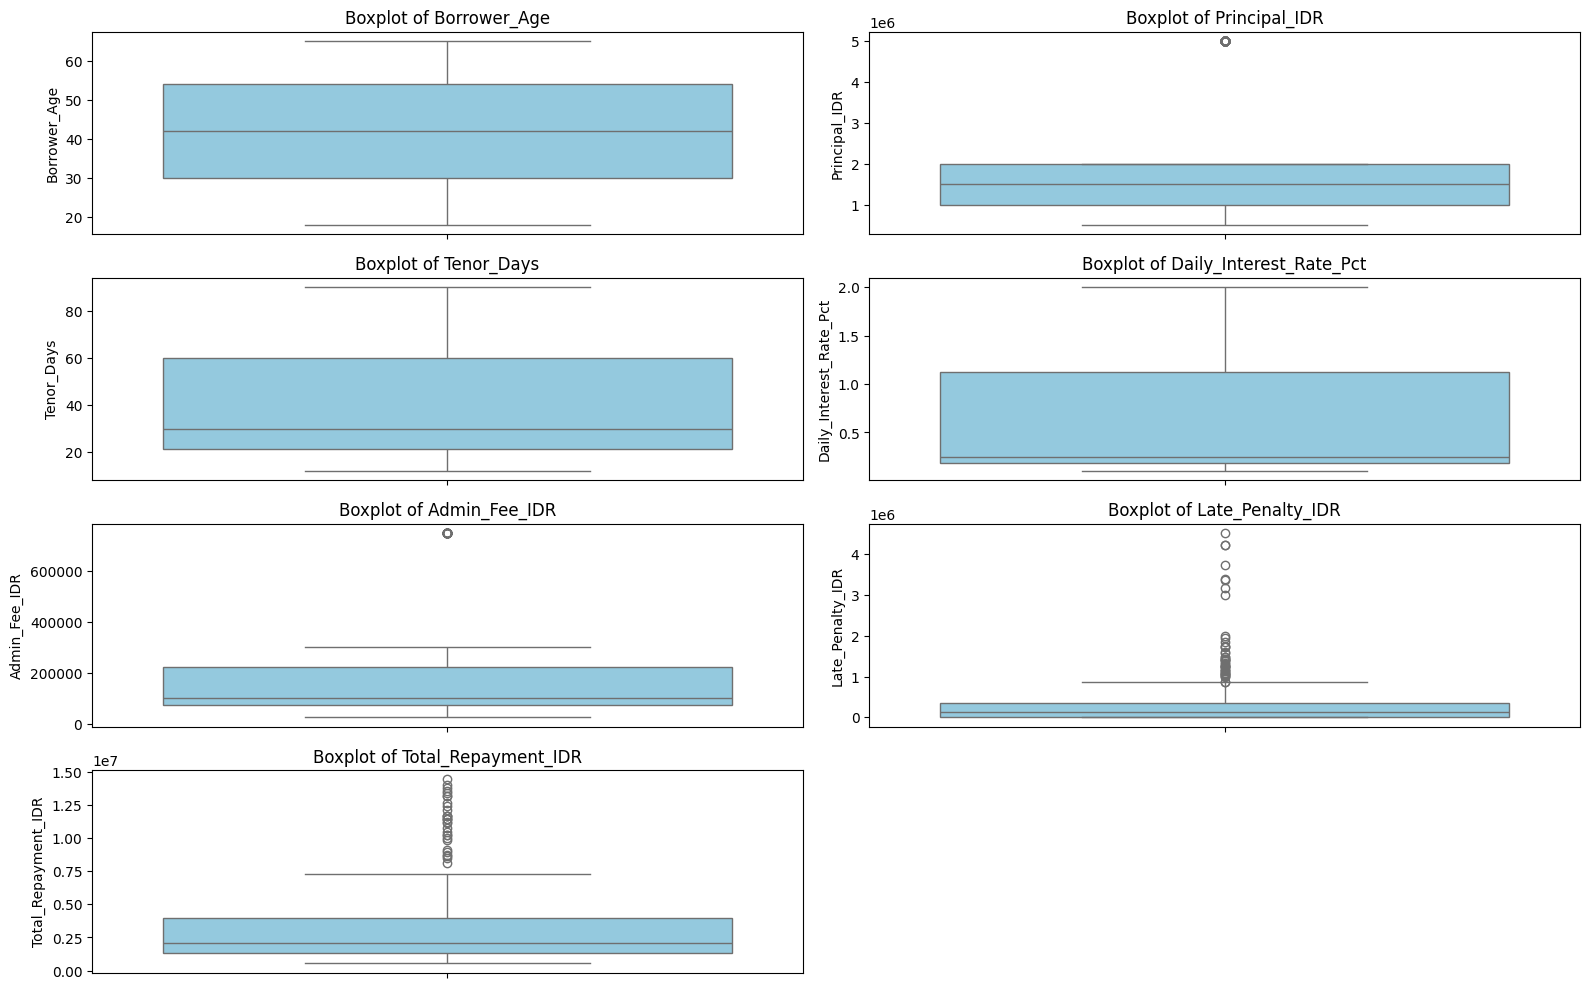

In [15]:
numeric_cols = [
    'Borrower_Age',
    'Principal_IDR',
    'Tenor_Days',
    'Daily_Interest_Rate_Pct',
    'Admin_Fee_IDR',
    'Late_Penalty_IDR',
    'Total_Repayment_IDR'
]

plt.figure(figsize=(16, 10))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(4, 2, i)
    sns.boxplot(y=df_clean[col], color='skyblue')
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()


In [16]:
outlier_results = []

for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    outlier_results.append({
        'Column': col,
        'Outlier_Count': len(outliers),
        'Lower_Bound': lower_bound,
        'Upper_Bound': upper_bound
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary)

,Column,Outlier_Count,Lower_Bound,Upper_Bound
0,Borrower_Age,0,-6.000,90.000
1,Principal_IDR,99,-500000.000,3500000.000
2,Tenor_Days,0,-36.250,117.750
3,Daily_Interest_Rate_Pct,0,-1.230,2.530
4,Admin_Fee_IDR,32,-150000.000,450000.000
5,Late_Penalty_IDR,44,-518407.875,864013.125
6,Total_Repayment_IDR,30,-2632558.250,7940277.750


Label Encoding

In [17]:

from sklearn.preprocessing import LabelEncoder

# Create a copy of df_clean
df_encoded = df_clean.copy()

# Select categorical columns, excluding date columns and Tenor_Days
categorical_cols = [
    col for col in df_encoded.select_dtypes(include=['object', 'category']).columns
    if col not in ['Disbursal_Date', 'Due_Date', 'Tenor_Days']
]

# Apply label encoding
label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()

    # Handle remaining missing values
    df_encoded[col] = df_encoded[col].fillna('Unknown').astype(str)

    # Encode categorical values
    df_encoded[col] = le.fit_transform(df_encoded[col])

    label_encoders[col] = le

# Display encoded data
display(df_encoded[categorical_cols].head())

# Check remaining missing values
print("Missing values after label encoding:")
print(df_encoded.isnull().sum())


,Transaction_ID,Platform_Name,Borrower_Income,Loan_Purpose,Loan_Status
0,0,4,1,4,1
1,1,5,3,4,0
2,2,3,1,1,0
3,3,1,3,1,0
4,4,0,0,0,0


Missing values after label encoding:
Transaction_ID              0
Platform_Name               0
Borrower_Age                0
Borrower_Income             0
Loan_Purpose                0
Principal_IDR               0
Tenor_Days                 13
Daily_Interest_Rate_Pct     0
Admin_Fee_IDR               0
Late_Penalty_IDR            0
Total_Repayment_IDR         0
Disbursal_Date              7
Due_Date                   14
Loan_Status                 0
dtype: int64


Standardization

In [19]:

from sklearn.preprocessing import StandardScaler

# Create a copy of the encoded dataset
df_encoded_standardized = df_encoded.copy()

# Original numerical columns only
numerical_cols = [
    'Borrower_Age',
    'Principal_IDR',
    'Daily_Interest_Rate_Pct',
    'Admin_Fee_IDR',
    'Late_Penalty_IDR',
    'Total_Repayment_IDR'
]

# Initialize StandardScaler
scaler = StandardScaler()

# Apply standardization
df_encoded_standardized[numerical_cols] = scaler.fit_transform(
    df_encoded_standardized[numerical_cols]
)

# Display standardized data
display(df_encoded_standardized[numerical_cols].head())

# Check the result
print("Mean after standardization:")
print(df_encoded_standardized[numerical_cols].mean().round(2))


,Borrower_Age,Principal_IDR,Daily_Interest_Rate_Pct,Admin_Fee_IDR,Late_Penalty_IDR,Total_Repayment_IDR
0,1.283563,1.920869,-0.761905,0.523798,-0.312337,0.982486
1,-0.344948,-0.315672,-0.528642,-0.336768,1.768616,0.362404
2,-1.455297,1.920869,-0.745244,0.523798,-0.312337,1.203616
3,1.727702,-0.954683,-0.745244,-0.336768,-0.347358,-0.881069
4,-0.048855,1.920869,-0.628612,0.523798,1.786441,1.369811


Mean after standardization:
Borrower_Age               0.0
Principal_IDR              0.0
Daily_Interest_Rate_Pct   -0.0
Admin_Fee_IDR             -0.0
Late_Penalty_IDR          -0.0
Total_Repayment_IDR        0.0
dtype: float64


In [20]:
df_encoded_standardized.head()

,Transaction_ID,Platform_Name,Borrower_Age,Borrower_Income,Loan_Purpose,Principal_IDR,Tenor_Days,Daily_Interest_Rate_Pct,Admin_Fee_IDR,Late_Penalty_IDR,Total_Repayment_IDR,Disbursal_Date,Due_Date,Loan_Status
0,0,4,1.283563,1,4,1.920869,14.0,-0.761905,0.523798,-0.312337,0.982486,2026-02-22,2026-03-28,1
1,1,5,-0.344948,3,4,-0.315672,60.0,-0.528642,-0.336768,1.768616,0.362404,2026-02-25,2026-03-22,0
2,2,3,-1.455297,1,1,1.920869,30.0,-0.745244,0.523798,-0.312337,1.203616,2026-02-19,2026-03-21,0
3,3,1,1.727702,3,1,-0.954683,30.0,-0.745244,-0.336768,-0.347358,-0.881069,2026-02-25,2026-03-24,0
4,4,0,-0.048855,0,0,1.920869,30.0,-0.628612,0.523798,1.786441,1.369811,NaT,NaT,0


In [21]:
df_clean.head()

,Transaction_ID,Platform_Name,Borrower_Age,Borrower_Income,Loan_Purpose,Principal_IDR,Tenor_Days,Daily_Interest_Rate_Pct,Admin_Fee_IDR,Late_Penalty_IDR,Total_Repayment_IDR,Disbursal_Date,Due_Date,Loan_Status
0,TXN-20260001,PinjamYuk,59.0,Factory Worker,Pay Off Other Debt,5000000.0,14.0,0.11,250000.0,138658.5,5797193.0,2026-02-22,2026-03-28,Late
1,TXN-20260002,PinjolCair,37.0,Gojek/Grab Driver,Pay Off Other Debt,1500000.0,60.0,0.25,100000.0,1319431.0,4088431.0,2026-02-25,2026-03-22,Defaulted
2,TXN-20260003,KreditPintar,22.0,Factory Worker,Daily Needs,5000000.0,30.0,0.12,250000.0,138658.5,6406562.0,2026-02-19,2026-03-21,Defaulted
3,TXN-20260004,DanaCepat,65.0,Gojek/Grab Driver,Daily Needs,500000.0,30.0,0.12,100000.0,118787.0,661787.0,2026-02-25,2026-03-24,Defaulted
4,TXN-20260005,AdaKami,41.0,Corporate Admin,Business Capital,5000000.0,30.0,0.19,250000.0,1329545.0,6864545.0,NaT,NaT,Defaulted


EDA

In [22]:
# Platform classification based on the provided labels
platform_status = {
    "PinjolCair": "Illegal",
    "DanaCepat": "Illegal",
    "DanaKilat": "Illegal",
    "PinjamYuk": "Legal",
    "KreditPintar": "Legal",
    "AdaKami": "Legal",
    "RupiahCepat": "Legal"
}

df_clean["Platform_Status"] = (
    df_clean["Platform_Name"]
    .map(platform_status)
    .fillna("Unverified")
)

print(
    df_clean[["Platform_Name", "Platform_Status"]]
    .drop_duplicates()
    .sort_values("Platform_Name")
)

  Platform_Name Platform_Status
4       AdaKami           Legal
3     DanaCepat         Illegal
8     DanaKilat         Illegal
2  KreditPintar           Legal
0     PinjamYuk           Legal
1    PinjolCair         Illegal
5   RupiahCepat           Legal


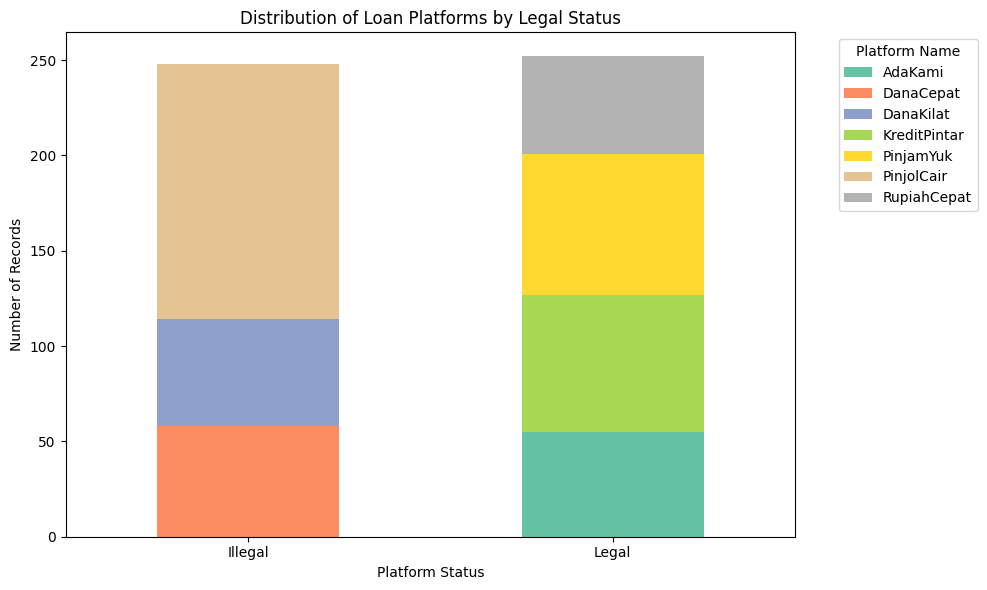

In [23]:
# Count platform distribution by legal status
platform_distribution = pd.crosstab(
    df_clean['Platform_Status'],
    df_clean['Platform_Name']
)

# Create stacked bar chart
platform_distribution.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='Set2'
)

plt.title('Distribution of Loan Platforms by Legal Status')
plt.xlabel('Platform Status')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)

plt.legend(
    title='Platform Name',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

In [24]:
# Convert Borrower_Age into discrete age groups
df_clean['Age_Group'] = pd.cut(
    df_clean['Borrower_Age'],
    bins=[-np.inf, 24, 40, np.inf],
    labels=['Young', 'Adult', 'Old']
)

# Display age group distribution
print(df_clean['Age_Group'].value_counts().sort_index())

Age_Group
Young     74
Adult    142
Old      284
Name: count, dtype: int64


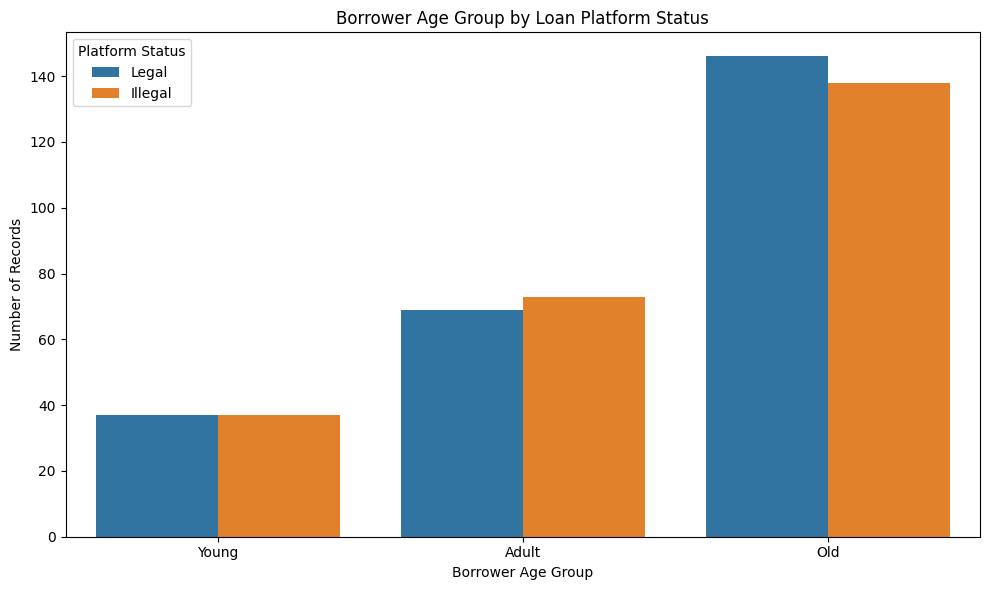

In [25]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_clean,
    x='Age_Group',
    hue='Platform_Status',
    order=['Young', 'Adult', 'Old']
)

plt.title('Borrower Age Group by Loan Platform Status')
plt.xlabel('Borrower Age Group')
plt.ylabel('Number of Records')
plt.legend(title='Platform Status')
plt.tight_layout()
plt.show()

In [26]:
age_status_distribution = pd.crosstab(
    df_clean['Age_Group'],
    df_clean['Platform_Status']
)

display(age_status_distribution)

Platform_Status,Illegal,Legal
Age_Group,,
Young,37,37
Adult,73,69
Old,138,146


In [27]:
age_status_percentage = pd.crosstab(
    df_clean['Age_Group'],
    df_clean['Platform_Status'],
    normalize='index'
) * 100

display(age_status_percentage.round(2))

Platform_Status,Illegal,Legal
Age_Group,,
Young,50.00,50.00
Adult,51.41,48.59
Old,48.59,51.41


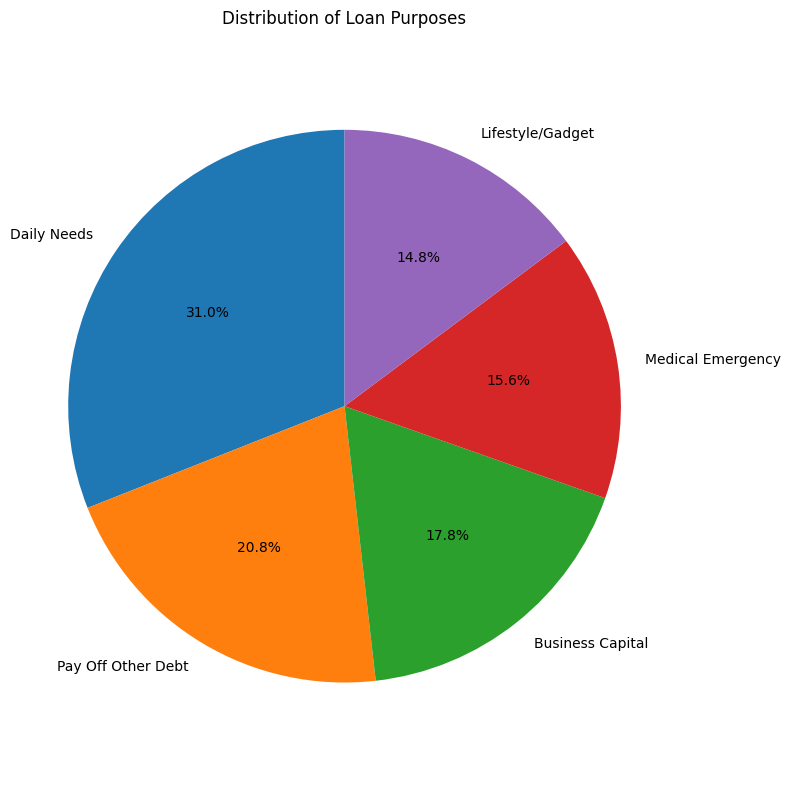

In [28]:
# Count loan purposes
loan_purpose_counts = df_clean['Loan_Purpose'].value_counts()

# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    loan_purpose_counts.values,
    labels=loan_purpose_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Loan Purposes')
plt.axis('equal')
plt.tight_layout()
plt.show()

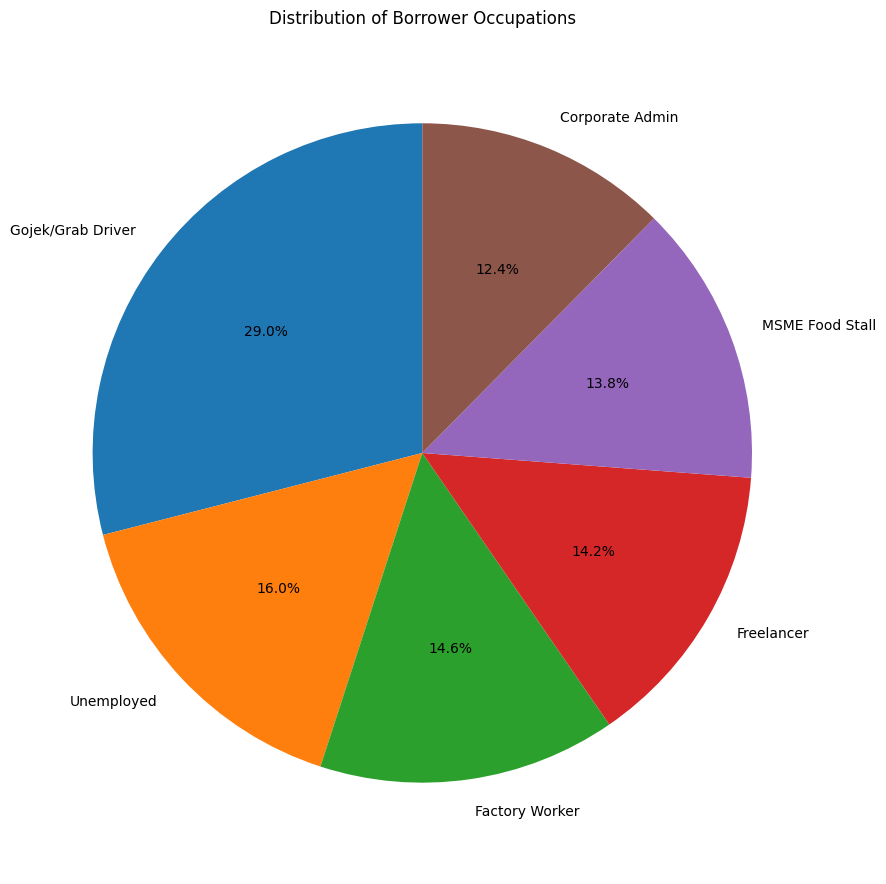

In [31]:
# Count borrower categories
borrower_counts = df_clean['Borrower_Income'].value_counts()

# Create pie chart
plt.figure(figsize=(9, 9))

plt.pie(
    borrower_counts.values,
    labels=borrower_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Borrower Occupations')
plt.axis('equal')
plt.tight_layout()
plt.show()

In [29]:
# Calculate average daily interest rate by platform
avg_interest = (
    df_clean.groupby('Platform_Name')['Daily_Interest_Rate_Pct']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

avg_interest.columns = ['Platform_Name', 'Average_Daily_Interest_Rate']

display(avg_interest.round(3))


,Platform_Name,Average_Daily_Interest_Rate
0,DanaKilat,1.397
1,PinjolCair,1.059
2,RupiahCepat,0.212
3,AdaKami,0.211
4,PinjamYuk,0.207
5,KreditPintar,0.198
6,DanaCepat,0.197


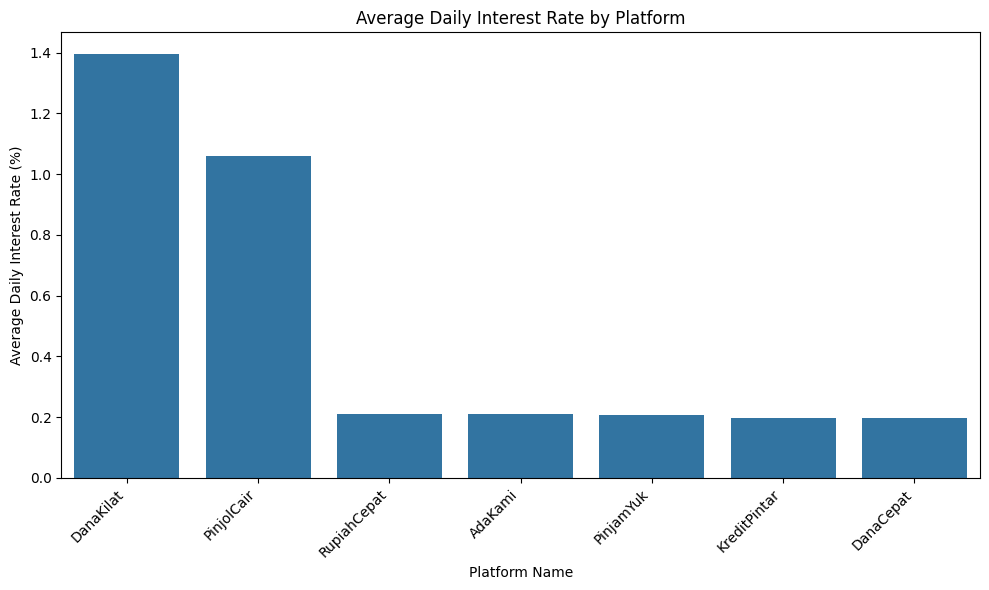

In [30]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=avg_interest,
    x='Platform_Name',
    y='Average_Daily_Interest_Rate'
)

plt.title('Average Daily Interest Rate by Platform')
plt.xlabel('Platform Name')
plt.ylabel('Average Daily Interest Rate (%)')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

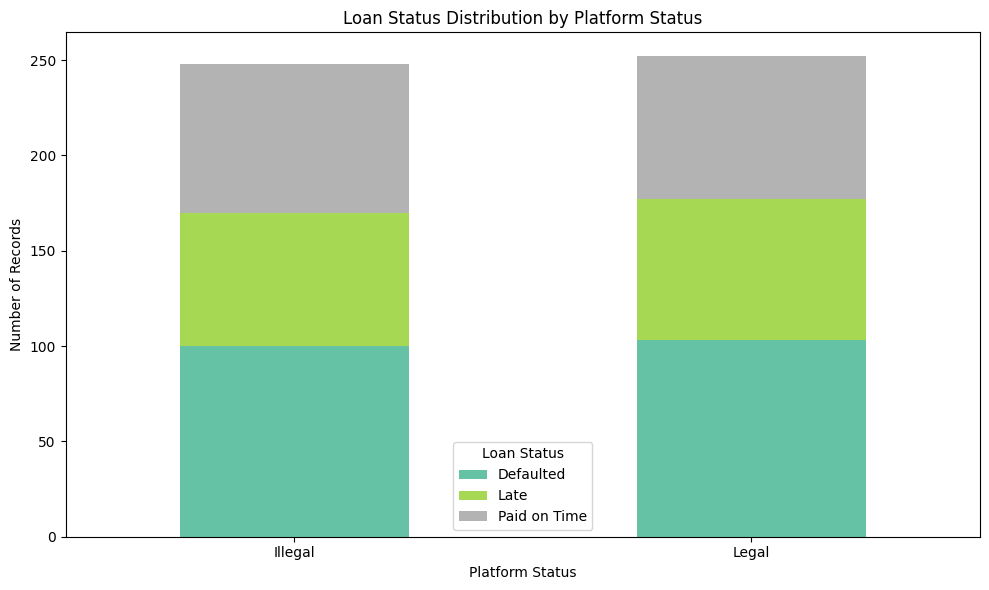

In [32]:
# Count loan status by platform status
loan_status_distribution = pd.crosstab(
    df_clean['Platform_Status'],
    df_clean['Loan_Status']
)

# Create stacked bar chart
loan_status_distribution.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='Set2'
)

plt.title('Loan Status Distribution by Platform Status')
plt.xlabel('Platform Status')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)
plt.legend(title='Loan Status')
plt.tight_layout()
plt.show()

In [33]:

loan_status_percentage = pd.crosstab(
    df_clean['Platform_Status'],
    df_clean['Loan_Status'],
    normalize='index'
) * 100

display(loan_status_percentage.round(2))

Loan_Status,Defaulted,Late,Paid on Time
Platform_Status,,,
Illegal,40.32,28.23,31.45
Legal,40.87,29.37,29.76
